# CSR vs Matrix-Free 2D Laplacian: Runtime and Memory
This notebook compares two ways to apply the same five-point discrete Laplacian on a 2D Cartesian grid:
1. CSR sparse matrix: explicitly assemble and store the discrete operator, then compute a sparse matrix-vector product.
2. Matrix-free stencil: store no sparse operator and evaluate the five-point stencil directly from neighboring grid values.
The purpose is not to claim that one representation is always superior, but to study the runtime and memory trade-offs for this simple structured-grid operator.

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import time

from numba import njit

from scipy.sparse import diags, eye, kron

## 1. Implement the same operator in two representations
For an $M\times M$ grid, the problem contains $M^2$ unknowns. The CSR version is formed with a Kronecker sum of one-dimensional second-difference matrices. The matrix-free version applies the equivalent neighbor stencil directly.

In [18]:
def build_laplacian_matrix(M):
    """Construct the 2D five-point Laplacian in CSR format.

    The Kronecker-sum construction corresponds to a Cartesian M x M grid.
    Values outside the domain are treated as zero, consistent with the
    matrix-free implementation below.
    """
    main = -2.0 * np.ones(M)
    off = np.ones(M - 1)

    T = diags(
        diagonals=[off, main, off],
        offsets=[-1, 0, 1],
        format="csr"
    )

    I = eye(M, format="csr")

    A = kron(I, T) + kron(T, I)

    return A.tocsr()

@njit
def laplacian_matrix_free(u, out):
    """Apply the same discrete Laplacian without explicitly storing A."""
    M = u.shape[0]

    for i in range(M):
        for j in range(M):

            value = -4.0 * u[i, j]

            if i > 0:
                value += u[i - 1, j]

            if i < M - 1:
                value += u[i + 1, j]

            if j > 0:
                value += u[i, j - 1]

            if j < M - 1:
                value += u[i, j + 1]

            out[i, j] = value

## 2. Verify numerical equivalence
A performance comparison is meaningful only if the two implementations apply the same operator. The following check compares their outputs on the same random field.

In [19]:
M = 100

u = np.random.rand(M, M)
out_mf = np.zeros_like(u)

A = build_laplacian_matrix(M)

# Matrix-free
laplacian_matrix_free(u, out_mf)

# Sparse matrix
out_csr = A @ u.ravel()

out_csr = out_csr.reshape(M, M)

print(np.allclose(out_mf, out_csr))

True


## 3. CSR operator-storage cost
CSR stores the nonzero values, column indices, and row pointers. For this five-point operator, the number of nonzeros grows linearly with the number of degrees of freedom, but the storage constant is significant. A matrix-free stencil stores the rule for applying the operator rather than the sparse matrix itself.

In [20]:
def csr_memory_bytes(A):
    """Return storage used by CSR values, column indices, and row pointers."""
    return (
        A.data.nbytes
        + A.indices.nbytes
        + A.indptr.nbytes
    )

M = 512
A = build_laplacian_matrix(M)
memory_bytes = csr_memory_bytes(A)
print("Unknowns:", M * M)
print("Nonzeros:", A.nnz)
print("CSR matrix memory:", memory_bytes / 1e6, "MB")

Unknowns: 262144
Nonzeros: 1308672
CSR matrix memory: 16.752644 MB


M= 128 unknowns=     16384 nnz=     81408 matrix memory=    1.04 MB
M= 256 unknowns=     65536 nnz=    326656 matrix memory=    4.18 MB
M= 512 unknowns=    262144 nnz=   1308672 matrix memory=   16.75 MB
M=1024 unknowns=   1048576 nnz=   5238784 matrix memory=   67.06 MB


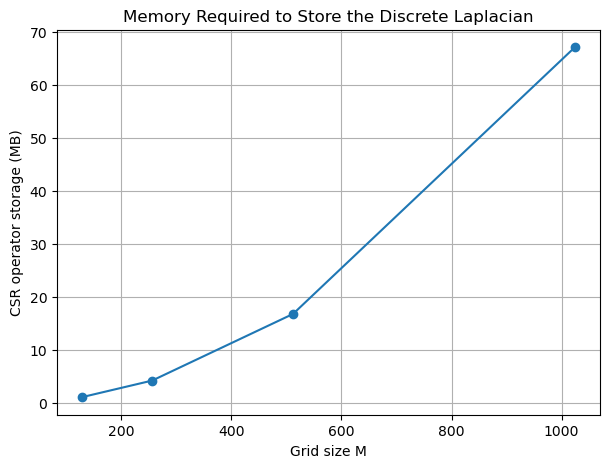

In [21]:
sizes = [128, 256, 512, 1024]

matrix_memory_mb = []

for M in sizes:
    A = build_laplacian_matrix(M)

    mem = csr_memory_bytes(A) / 1e6

    matrix_memory_mb.append(mem)

    print(
        f"M={M:4d}",
        f"unknowns={M*M:10d}",
        f"nnz={A.nnz:10d}",
        f"matrix memory={mem:8.2f} MB"
    )
    
plt.figure(figsize=(7, 5))
plt.plot(sizes,matrix_memory_mb,marker="o")
plt.xlabel("Grid size M")
plt.ylabel("CSR operator storage (MB)")
plt.title("Memory Required to Store the Discrete Laplacian")
plt.grid()
plt.show()

## 4. Operator-application runtime
The Numba matrix-free kernel is warmed up before timing so JIT compilation is excluded. Each reported value is the median of repeated wall-clock measurements. Results are specific to this machine and software stack.

In [22]:
def benchmark(func, repeats=5):
    times = []

    for _ in range(repeats):
        start = time.perf_counter()
        func()
        end = time.perf_counter()

        times.append(end - start)

    return np.median(times)

M = 1024
u = np.random.rand(M, M)
out_mf = np.zeros_like(u)
A = build_laplacian_matrix(M)
# Numba warm-up
laplacian_matrix_free(u, out_mf)
t_mf = benchmark(lambda: laplacian_matrix_free(u, out_mf))
u_flat = u.ravel()
t_csr = benchmark(lambda: A @ u_flat)
print("Matrix-free:", t_mf, "seconds")
print("CSR:", t_csr, "seconds")
print("CSR / Matrix-free:", t_csr / t_mf)

Matrix-free: 0.0010578329674899578 seconds
CSR: 0.003712667152285576 seconds
CSR / Matrix-free: 3.5096912900106045


128 matrix-free = 4.683295264840126e-05 CSR = 0.0001366250216960907
256 matrix-free = 7.654097862541676e-05 CSR = 0.00023199990391731262
512 matrix-free = 0.00031933304853737354 CSR = 0.0012389160692691803
1024 matrix-free = 0.0008909581229090691 CSR = 0.0033315829932689667


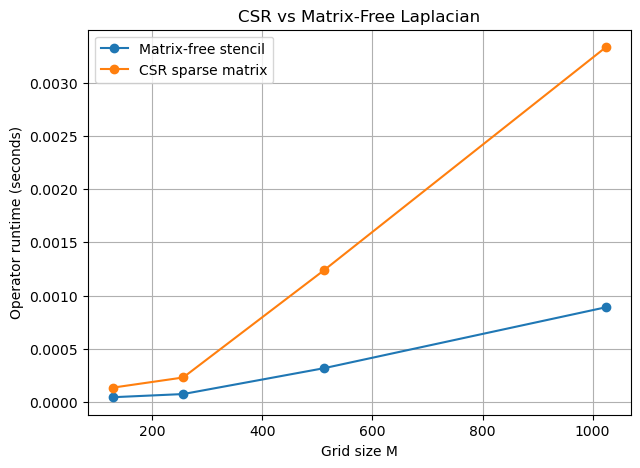

In [23]:
sizes = [128, 256, 512, 1024]

csr_times = []
mf_times = []

for M in sizes:

    u = np.random.rand(M, M)
    out_mf = np.zeros_like(u)

    A = build_laplacian_matrix(M)

    # warm-up
    laplacian_matrix_free(u, out_mf)

    t_mf = benchmark(
        lambda: laplacian_matrix_free(u, out_mf),
        repeats=5
    )

    u_flat = u.ravel()

    t_csr = benchmark(
        lambda: A @ u_flat,
        repeats=5
    )

    mf_times.append(t_mf)
    csr_times.append(t_csr)

    print(
        M,
        "matrix-free =", t_mf,
        "CSR =", t_csr
    )

plt.figure(figsize=(7, 5))

plt.plot(
    sizes,
    mf_times,
    marker="o",
    label="Matrix-free stencil"
)

plt.plot(
    sizes,
    csr_times,
    marker="o",
    label="CSR sparse matrix"
)

plt.xlabel("Grid size M")
plt.ylabel("Operator runtime (seconds)")
plt.title("CSR vs Matrix-Free Laplacian")
plt.legend()
plt.grid()

plt.show()

## 5. Memory scaling to 2.36 million degrees of freedom
The next experiment separates operator storage from the input/output vectors required by both implementations. At $1536^2 = 2{,}359{,}296$ unknowns, the explicit CSR operator requires substantial additional memory, while the matrix-free representation has no explicitly stored sparse operator.

In [24]:
sizes = [128, 256, 512, 1024, 1536]

dofs = []
csr_memory_mb = []
matrix_free_operator_mb = []

for M in sizes:
    A = build_laplacian_matrix(M)

    ndof = M * M
    csr_mem = csr_memory_bytes(A) / 1e6

    dofs.append(ndof)
    csr_memory_mb.append(csr_mem)

    # We do not explicitly store the operator
    matrix_free_operator_mb.append(0.0)

    print(
        f"M={M:4d} | "
        f"DOFs={ndof:10d} | "
        f"CSR operator={csr_mem:8.2f} MB"
    )

M= 128 | DOFs=     16384 | CSR operator=    1.04 MB
M= 256 | DOFs=     65536 | CSR operator=    4.18 MB
M= 512 | DOFs=    262144 | CSR operator=   16.75 MB
M=1024 | DOFs=   1048576 | CSR operator=   67.06 MB
M=1536 | DOFs=   2359296 | CSR operator=  150.92 MB


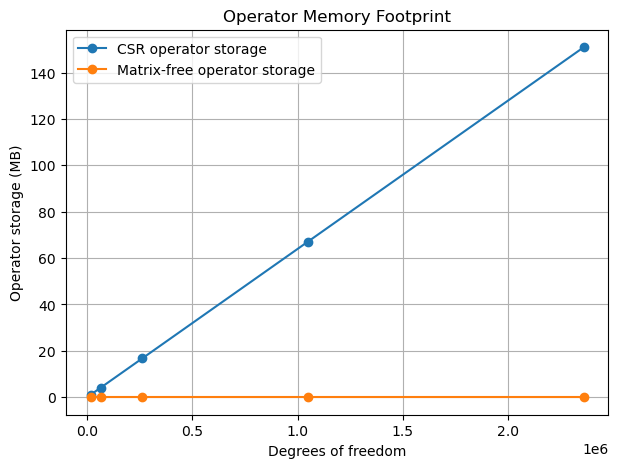

In [25]:
plt.figure(figsize=(7, 5))

plt.plot(
    dofs,
    csr_memory_mb,
    marker="o",
    label="CSR operator storage"
)

plt.plot(
    dofs,
    matrix_free_operator_mb,
    marker="o",
    label="Matrix-free operator storage"
)

plt.xlabel("Degrees of freedom")
plt.ylabel("Operator storage (MB)")
plt.title("Operator Memory Footprint")
plt.legend()
plt.grid()

plt.show()

## Approximate working-memory comparison
For a simple operator application, both methods need an input and an output float64 vector. The estimate below adds those vectors to the CSR operator storage. It intentionally does not attempt to measure all Python/SciPy temporary allocations or process overhead.

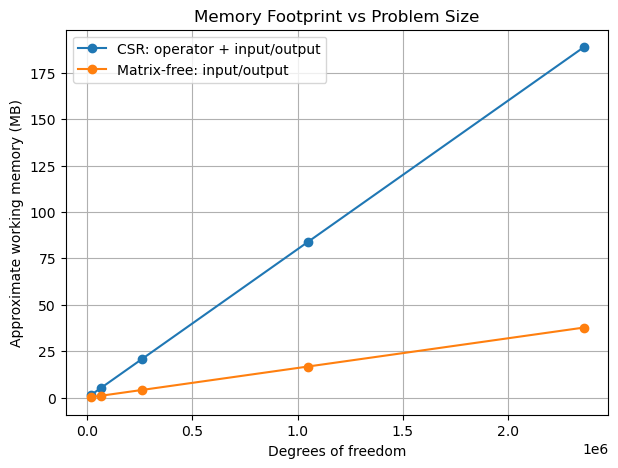

In [26]:
csr_total_mb = []
mf_total_mb = []

for M in sizes:
    A = build_laplacian_matrix(M)

    ndof = M * M

    vector_bytes = 2 * ndof * 8

    csr_total = vector_bytes + csr_memory_bytes(A)
    mf_total = vector_bytes

    csr_total_mb.append(csr_total / 1e6)
    mf_total_mb.append(mf_total / 1e6)

plt.figure(figsize=(7, 5))

plt.plot(
    dofs,
    csr_total_mb,
    marker="o",
    label="CSR: operator + input/output"
)

plt.plot(
    dofs,
    mf_total_mb,
    marker="o",
    label="Matrix-free: input/output"
)

plt.xlabel("Degrees of freedom")
plt.ylabel("Approximate working memory (MB)")
plt.title("Memory Footprint vs Problem Size")
plt.legend()
plt.grid()

plt.show()

## 6. Runtime normalized by problem size
Dividing runtime by the number of unknowns gives a simple view of how per-DOF application cost changes as the problem size grows.

In [29]:
sizes = [128, 256, 512, 1024]

mf_time_per_dof = []
csr_time_per_dof = []

for M in sizes:

    u = np.random.rand(M, M)
    out_mf = np.zeros_like(u)

    A = build_laplacian_matrix(M)

    # warm-up
    laplacian_matrix_free(u, out_mf)

    t_mf = benchmark(
        lambda: laplacian_matrix_free(u, out_mf),
        repeats=5
    )

    u_flat = u.ravel()

    t_csr = benchmark(
        lambda: A @ u_flat,
        repeats=5
    )

    ndof = M * M

    mf_time_per_dof.append(t_mf / ndof)
    csr_time_per_dof.append(t_csr / ndof)

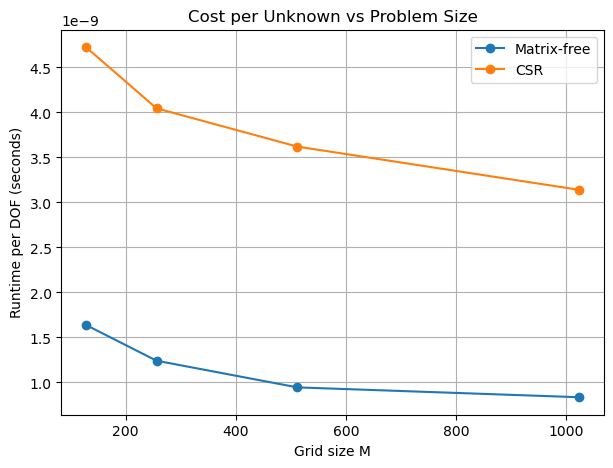

In [30]:
plt.figure(figsize=(7, 5))

plt.plot(
    sizes,
    mf_time_per_dof,
    marker="o",
    label="Matrix-free"
)

plt.plot(
    sizes,
    csr_time_per_dof,
    marker="o",
    label="CSR"
)

plt.xlabel("Grid size M")
plt.ylabel("Runtime per DOF (seconds)")
plt.title("Cost per Unknown vs Problem Size")
plt.legend()
plt.grid()

plt.show()

## Main observations
- The CSR and matrix-free implementations are numerically equivalent for the tested operator.
- In the recorded $1024^2$ benchmark, the matrix-free kernel applied the operator about 3.8x faster than SciPy CSR multiplication.
- At $1536^2$ (2.36M DOF), the estimated working-memory model gives roughly 5x lower memory for the matrix-free case because the sparse operator is not stored.
- The result is consistent with the broader idea that structured matrix-free methods can reduce data movement and storage, but the magnitude is implementation- and hardware-dependent.

## Limitations and next steps
- This is an operator benchmark, not an advanced PDE solver or a study of iterative-solver convergence.
- The comparison is serial and single-node; it does not test MPI communication, OpenMP scaling, or GPU execution.